# 01 · Dataset audit and train-image EDA

**Question.** What images are available, are the split IDs valid, and what properties should the denoising model expect?  
**Decision boundary.** Audit integrity across all splits, but examine image content and simulated noise only on **train**. The final test set stays outside feature and parameter choices.  
**Expected outputs.** Saved charts in `notebooks/figures/` and a machine-readable `results/eda_summary.json`. This notebook does not fit or select a model.

## Setup, source, and fixed protocol

The Berkeley archive URL, SHA-256, split IDs, grayscale resize rule, and seed come from `data/manifest.json` and project source. The full license/use note is in the manifest and project README.

In [1]:
from pathlib import Path
import csv, hashlib, json, sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/manifest.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run the notebook from mini-project/ or a child folder")
sys.path.insert(0, str(ROOT))
from src.core import noisy_image, filters, features, psnr

manifest = json.loads((ROOT / "data/manifest.json").read_text(encoding="utf-8"))
splits = manifest["splits"]
FIG = ROOT / "notebooks/figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 302
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
def image(split, image_id):
    value = cv2.imread(str(ROOT / "data/clean" / split / f"{image_id}.png"), cv2.IMREAD_GRAYSCALE)
    if value is None:
        raise FileNotFoundError(f"Missing image: {split}/{image_id}")
    return value
print("Project:", ROOT.name, "| seed:", SEED, "| source:", manifest["source_dataset"])

Project: mini-project | seed: 302 | source: Berkeley Segmentation Dataset BSDS300, images archive


Archive SHA-256 verified: 7f855a00491a3f1ca2609b3c96651b88b265fe59b70a7b007cc7a2850a22b386
Disjoint, complete split counts: {'train': 60, 'val': 12, 'pilot': 20, 'test': 20}


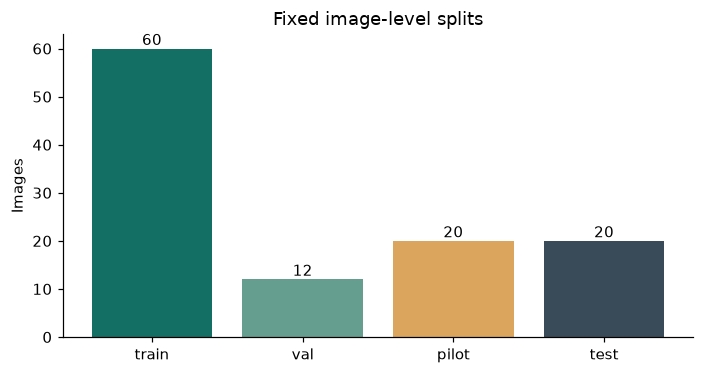

In [2]:
archive = ROOT / "data/raw/BSDS300-images.tgz"
actual_sha = hashlib.sha256(archive.read_bytes()).hexdigest()
assert actual_sha == manifest["source_sha256"]
all_ids = [i for ids in splits.values() for i in ids]
assert len(all_ids) == len(set(all_ids)), "An image ID crosses splits"
for split, ids in splits.items():
    assert all((ROOT / "data/clean" / split / f"{i}.png").is_file() for i in ids)
print("Archive SHA-256 verified:", actual_sha)
print("Disjoint, complete split counts:", {s: len(v) for s, v in splits.items()})
fig, ax = plt.subplots(figsize=(6.5, 3.5))
labels = list(splits)
bars = ax.bar(labels, [len(splits[k]) for k in labels], color=["#136f63", "#659d8e", "#dba55e", "#394b59"])
ax.bar_label(bars)
ax.set(ylabel="Images", title="Fixed image-level splits")
fig.tight_layout(); fig.savefig(FIG / "eda_split_counts.png", dpi=160); plt.show()

## Data quality and leakage audit

Only dimensions, encoding, exact hashes, and small perceptual hashes are inspected across splits. This is a one-time integrity check. Any feature or method choice later in this notebook uses train pixels only.

In [3]:
records = []
hashes = {}
perceptual = {}
for split, ids in splits.items():
    for image_id in ids:
        path = ROOT / "data/clean" / split / f"{image_id}.png"
        pixels = image(split, image_id)
        assert pixels.ndim == 2 and pixels.dtype == np.uint8
        height, width = pixels.shape
        assert max(height, width) <= 256
        records.append((split, image_id, width, height))
        hashes[(split, image_id)] = hashlib.sha256(path.read_bytes()).hexdigest()
        tiny = cv2.resize(pixels, (9, 8), interpolation=cv2.INTER_AREA)
        perceptual[(split, image_id)] = (tiny[:, 1:] > tiny[:, :-1]).flatten()
exact_cross_split = [(a, b) for a in hashes for b in hashes
                     if a < b and a[0] != b[0] and hashes[a] == hashes[b]]
near_cross_split = [(a, b, int(np.count_nonzero(perceptual[a] != perceptual[b])))
                    for a in perceptual for b in perceptual
                    if a < b and a[0] != b[0]
                    and np.count_nonzero(perceptual[a] != perceptual[b]) <= 4]
print("Images decoded:", len(records), "| corrupt/missing: 0")
print("Exact cross-split duplicates:", len(exact_cross_split))
print("Cross-split dHash candidates (Hamming <= 4; inspect manually):", len(near_cross_split))
print("First candidate pairs:", near_cross_split[:5])

Images decoded: 112 | corrupt/missing: 0
Exact cross-split duplicates: 0
Cross-split dHash candidates (Hamming <= 4; inspect manually): 0
First candidate pairs: []


## What do train images look like?

A seeded sample grid makes content and preprocessing visible. The images below come from train only; the grid is descriptive, not a test result.

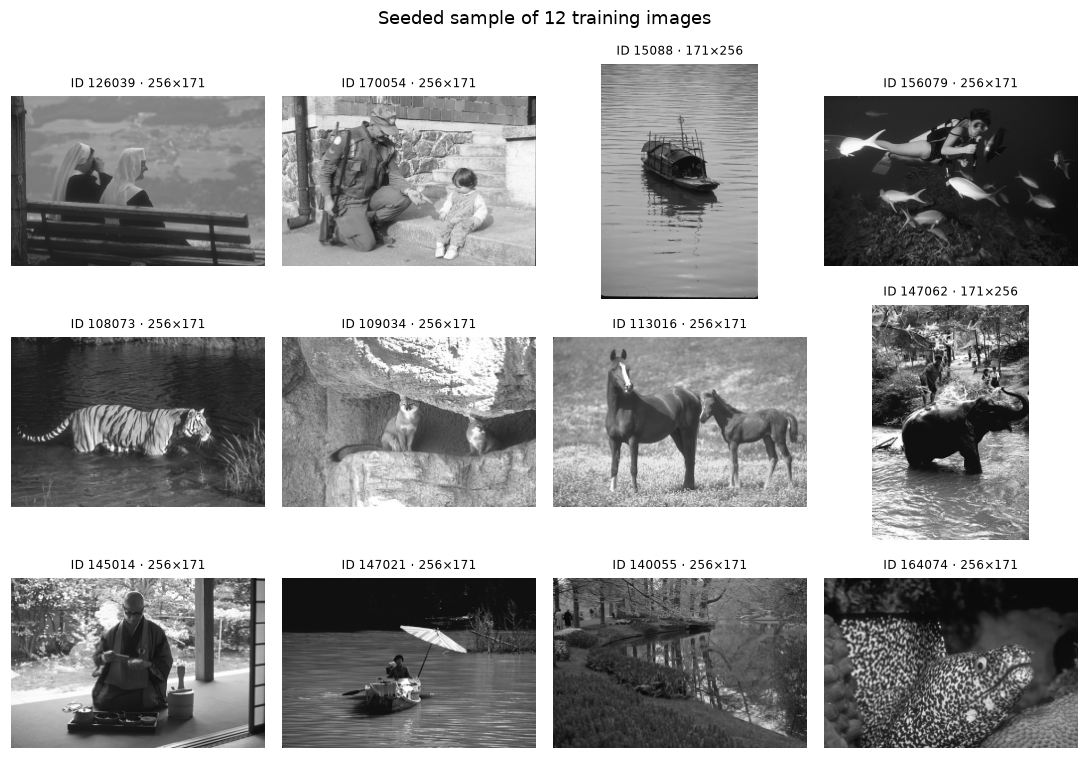

In [4]:
rng = np.random.default_rng(SEED)
chosen = rng.choice(splits["train"], size=12, replace=False)
fig, axes = plt.subplots(3, 4, figsize=(10, 7.3))
for ax, image_id in zip(axes.flat, chosen):
    pixels = image("train", image_id)
    ax.imshow(pixels, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"ID {image_id} · {pixels.shape[1]}×{pixels.shape[0]}", fontsize=8)
    ax.axis("off")
fig.suptitle("Seeded sample of 12 training images")
fig.tight_layout(); fig.savefig(FIG / "eda_train_gallery.png", dpi=160); plt.show()

## Resolution and pixel statistics

The model sees gray pixel values from 0 to 255. Brightness and contrast can vary across natural scenes. The histograms and scatter below use all 60 train images, never pilot or final-test pixels.

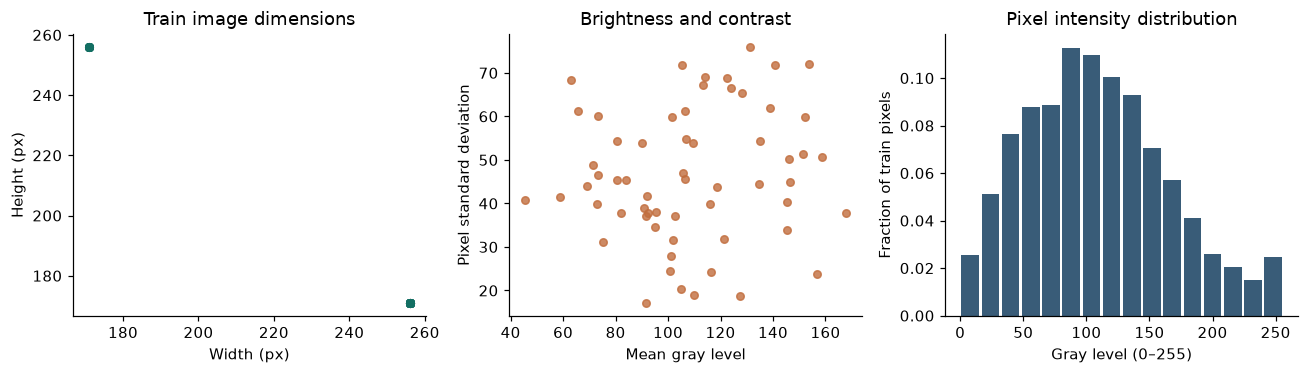

Train dimensions (width × height), unique: [(np.int64(171), np.int64(256)), (np.int64(256), np.int64(171))]
Train mean brightness range: 45.58 to 167.75
Train pixel std range: 17.16 to 75.95


In [5]:
train_arrays = [image("train", i) for i in splits["train"]]
train_width = np.array([a.shape[1] for a in train_arrays])
train_height = np.array([a.shape[0] for a in train_arrays])
train_mean = np.array([a.mean() for a in train_arrays])
train_std = np.array([a.std() for a in train_arrays])
hist = np.sum([np.histogram(a, bins=np.arange(0, 257, 16))[0]
               for a in train_arrays], axis=0)
hist = hist / hist.sum()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].scatter(train_width, train_height, s=24, alpha=.8, c="#136f63")
axes[0].set(xlabel="Width (px)", ylabel="Height (px)", title="Train image dimensions")
axes[1].scatter(train_mean, train_std, s=24, alpha=.8, c="#c16d3d")
axes[1].set(xlabel="Mean gray level", ylabel="Pixel standard deviation", title="Brightness and contrast")
axes[2].bar(np.arange(16)*16+8, hist, width=14, color="#395c78")
axes[2].set(xlabel="Gray level (0–255)", ylabel="Fraction of train pixels", title="Pixel intensity distribution")
fig.tight_layout(); fig.savefig(FIG / "eda_train_properties.png", dpi=160); plt.show()
print("Train dimensions (width × height), unique:", sorted(set(zip(train_width, train_height))))
print("Train mean brightness range:", round(float(train_mean.min()), 2), "to", round(float(train_mean.max()), 2))
print("Train pixel std range:", round(float(train_std.min()), 2), "to", round(float(train_std.max()), 2))

## Simulated Gaussian noise on a train image

The same clean train image is corrupted independently at three documented σ levels. Clipping to [0,255] means the measured pixel difference is not exactly a perfect Gaussian near black or white.

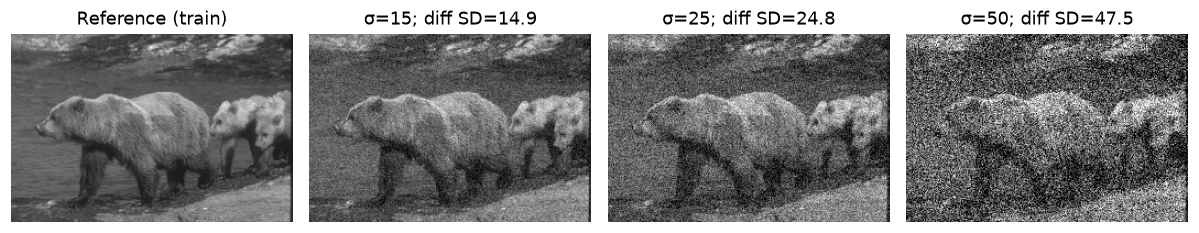

{
  "15": {
    "measured_difference_std": 14.946830749511719,
    "clipped_fraction": 0.0006853070175438596
  },
  "25": {
    "measured_difference_std": 24.84532928466797,
    "clipped_fraction": 0.007492690058479532
  },
  "50": {
    "measured_difference_std": 47.53064727783203,
    "clipped_fraction": 0.06432748538011696
  }
}


In [6]:
example_id = splits["train"][0]
clean = image("train", example_id)
fig, axes = plt.subplots(1, 4, figsize=(11, 3.3))
axes[0].imshow(clean, cmap="gray", vmin=0, vmax=255); axes[0].set_title("Reference (train)")
noise_checks = {}
for ax, sigma in zip(axes[1:], (15, 25, 50)):
    noisy = noisy_image(clean, sigma, example_id, SEED)
    difference = noisy.astype(np.float32) - clean.astype(np.float32)
    noise_checks[str(sigma)] = {"measured_difference_std": float(difference.std()),
                                "clipped_fraction": float(((noisy == 0) | (noisy == 255)).mean())}
    ax.imshow(noisy, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"σ={sigma}; diff SD={difference.std():.1f}")
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig(FIG / "eda_noise_levels.png", dpi=160); plt.show()
print(json.dumps(noise_checks, indent=2))

## Recorded findings and limits

The JSON below records audit counts and train-only summary values for the report. dHash is a screening tool, not proof that two images depict the same scene. For method selection, use train/validation as specified in `src/experiment.py`; the final test set must remain locked.

In [7]:
eda = {
  "source": manifest["source"], "source_sha256": actual_sha,
  "seed": SEED, "split_counts": {s: len(v) for s, v in splits.items()},
  "image_count_audited": len(records),
  "exact_cross_split_duplicates": len(exact_cross_split),
  "dhash_candidates_cross_split_hamming_le_4": len(near_cross_split),
  "train_width_min_max": [int(train_width.min()), int(train_width.max())],
  "train_height_min_max": [int(train_height.min()), int(train_height.max())],
  "train_brightness_min_max": [float(train_mean.min()), float(train_mean.max())],
  "train_contrast_std_min_max": [float(train_std.min()), float(train_std.max())],
  "noise_example_train_id": example_id, "noise_checks": noise_checks,
  "software": {"numpy": np.__version__, "opencv": cv2.__version__},
}
target = ROOT / "results/eda_summary.json"
target.write_text(json.dumps(eda, indent=2), encoding="utf-8")
print("Saved", target)

Saved C:\LEARNING\FPT_NVH\FAL2026\IMP302\mini-project\results\eda_summary.json
